# Class 1 - From a regression line to a neural network

**Goes with slides 1-26 (Part I, "Basics of artificial neural networks").**

The lecture made three claims that this notebook puts in your hands, on real data:

1. Fitting a model is **induction** - you guess a rule from observations, and the rule is only ever
   probabilistic (slides 4-7).
2. An artificial neuron **is** a linear regression with a nonlinearity bolted on (slides 9-11), and a
   network is just many of them (slides 13-16).
3. Training means **walking downhill on a loss function** (slides 17, 22-23), and if you walk too far
   you overfit, which is why a test set exists (slides 19-21).

The data: 908 chemicals with 6 molecular descriptors each, and their measured acute toxicity to the
fathead minnow (*Pimephales promelas*), 96-hour LC50. The target is `-log10(mol/L)`, so **larger means
more toxic**. This is a real QSAR dataset, small enough that every experiment below finishes in seconds.

Exercises are marked ✏️ and open questions ❓. **The answers are in this notebook**, in the cell right
after the question - try it yourself before you open them.

## Setup

In [ ]:
# @title Setup: imports, data loading and helpers (run me)

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")          # sklearn convergence chatter, not interesting here
RNG = 0                                    # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")


DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

FISH_COLUMNS = ["CIC0", "SM1_Dz", "GATS1i", "NdsCH", "NdssC", "MLOGP", "LC50"]
AQUATIC_COLUMNS = ["TPSA", "SAacc", "H050", "MLOGP", "RDCHI", "GATS1p", "nN", "C040", "LC50"]


def load_fish():
    """Fathead minnow 96 h LC50 for 908 chemicals (UCI QSAR fish toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_fish_toxicity.csv", sep=";", header=None, names=FISH_COLUMNS)


def load_aquatic():
    """Daphnia magna 48 h LC50 for 546 chemicals (UCI QSAR aquatic toxicity)."""
    return pd.read_csv(DATA_DIR / "qsar_aquatic_toxicity.csv", sep=";", header=None, names=AQUATIC_COLUMNS)


def xy(df):
    """Descriptor matrix and target vector."""
    return df.drop(columns="LC50").values, df["LC50"].values

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


## Part 1 - Induction: a rule guessed from observations

Slide 4 contrasts deduction (*theory → observation*) with induction (*observation → rule*). Machine
learning is industrial-scale induction, and slide 6 warns with an asterisk that letting computers do it
is **dangerous**. Before any model, look at what we are inducing from.

In [ ]:
fish = load_fish()
print(fish.shape)
fish.head()

(908, 7)


,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
0,3.260,0.829,1.676,0,1,1.453,3.770
1,2.189,0.580,0.863,0,0,1.348,3.115
2,2.125,0.638,0.831,0,0,1.348,3.531
3,3.027,0.331,1.472,1,0,1.807,3.510
4,2.094,0.827,0.860,0,0,1.886,5.390


In [ ]:
fish.describe()

,CIC0,SM1_Dz,GATS1i,NdsCH,NdssC,MLOGP,LC50
count,908.000,908.000,908.000,908.000,908.000,908.000,908.000
mean,2.898,0.628,1.294,0.229,0.486,2.109,4.064
std,0.756,0.428,0.394,0.605,0.861,1.433,1.456
min,0.667,0.000,0.396,0.000,0.000,-2.884,0.053
25%,2.347,0.223,0.951,0.000,0.000,1.209,3.152
50%,2.934,0.570,1.240,0.000,0.000,2.127,3.987
75%,3.407,0.893,1.562,0.000,1.000,3.105,4.907
max,5.926,2.171,2.920,4.000,6.000,6.515,9.612


The six descriptors are numbers a program computes from the molecular structure (slide 25 calls this
*featurization*): `MLOGP` is a calculated octanol/water partition coefficient - roughly, how greasy the
molecule is - and the others are topological indices.

✏️ **Exercise 1.** Which single descriptor is most strongly associated with toxicity? Compute the
correlation of each descriptor with `LC50` and plot the best one against the target.

GATS1i   -0.398
NdsCH     0.172
NdssC     0.172
CIC0      0.292
SM1_Dz    0.411
MLOGP     0.652
Name: LC50, dtype: float64


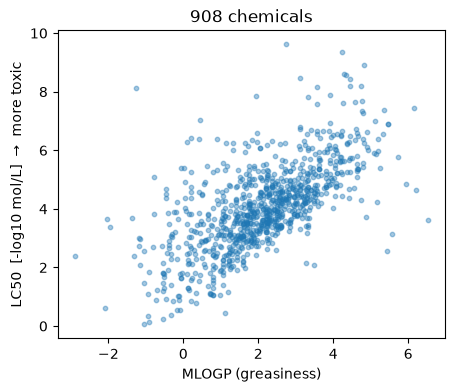

In [ ]:
print(fish.corr()["LC50"].drop("LC50").sort_values())

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(fish["MLOGP"], fish["LC50"], s=10, alpha=0.4)
ax.set_xlabel("MLOGP (greasiness)")
ax.set_ylabel("LC50  [-log10 mol/L]  →  more toxic")
ax.set_title("908 chemicals")
plt.show()

**Answer.** `MLOGP`, at r = 0.65. Greasier molecules are more toxic - they cross membranes and partition
into lipid, the classical "narcosis" baseline of aquatic toxicology. `SM1_Dz` follows at 0.41 and
`GATS1i` is the one clearly *negative* association, -0.40.

Two things worth noticing on the scatter plot, because they come back all afternoon: the trend is real
but the scatter around it is wide, and there is no visible second cluster - one rule, with noise, is a
defensible assumption here.

## Part 2 - Regression as a box with parameters inside

Slide 9 draws regression as a box: inputs $x_1, x_2$ go in, weights $w_1, w_2, w_3$ sit inside, a number
comes out.

$$y(x_1, x_2 \mid w) = w_1 x_1 + w_2 x_2 + w_3$$

We *assumed* the functional form (a plane) and we *induce* the weights. Let us do exactly that: first
with one descriptor, then with all six.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(5, shuffle=True, random_state=RNG)
X, y = xy(fish)

one = LinearRegression().fit(fish[["MLOGP"]], y)
print(f"one descriptor:  LC50 = {one.coef_[0]:.3f} * MLOGP + {one.intercept_:.3f}")
print("  5-fold CV R2 =", round(cross_val_score(LinearRegression(), fish[["MLOGP"]], y, cv=cv, scoring="r2").mean(), 3))

allsix = LinearRegression().fit(X, y)
print("\nall six descriptors:")
for name, w in zip(FISH_COLUMNS[:-1], allsix.coef_):
    print(f"  {name:>7s}  {w:+.3f}")
print(f"  {'bias':>7s}  {allsix.intercept_:+.3f}")
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
print("  5-fold CV R2 =", round(scores.mean(), 3), "±", round(scores.std(), 3))

one descriptor:  LC50 = 0.662 * MLOGP + 2.668
  5-fold CV R2 = 0.408

all six descriptors:
     CIC0  +0.386
   SM1_Dz  +1.256
   GATS1i  -0.746
    NdsCH  +0.414
    NdssC  +0.064
    MLOGP  +0.390
     bias  +2.175
  5-fold CV R2 = 0.557 ± 0.043


`MLOGP` alone explains R² = 0.41 of the variance out of sample; all six together reach 0.56.

❓ **Question.** Slide 8 says the induced rule "may be precious per se", and that you may want to
sacrifice accuracy for interpretability. What exactly does the coefficient `MLOGP = +0.39` tell a
toxicologist - and why is it *not* the same number as the slope of the one-descriptor fit?

**Answer.** It says: *holding the other five descriptors fixed*, one unit of MLOGP buys +0.39 units of
LC50, i.e. a 0.39-decade (≈2.5×) drop in the lethal concentration. That is a dose-response statement a
toxicologist can argue with, which is the point of slide 8.

It differs from the single-descriptor slope because the descriptors are correlated: alone, `MLOGP`
also carries the effect of everything that travels with greasiness; in the six-descriptor model those
contributions have been handed to `SM1_Dz` and the others. This is why "the coefficient of X" is only
meaningful relative to what else is in the model - a point that will matter far more when the model is a
black box (slide 24) and there are no coefficients at all.

## Part 3 - One artificial neuron

Slide 10: take the regression box, add a nonlinear activation, and you have an artificial neuron.

$$p = w_1 x_1 + \dots + w_k x_k + b, \qquad y = \max(0, p)$$

Slide 12 insists: this is a mathematical model, **not** a model of a biological neuron. Let us write one
in four lines of numpy and check slide 11's claim that a neuron with no nonlinearity is exactly a linear
regression.

In [ ]:
def neuron(x, w, b, activation="relu"):
    """One artificial neuron: scalar product, then a nonlinearity."""
    p = x @ w + b
    return np.maximum(0.0, p) if activation == "relu" else p


w, b = allsix.coef_, allsix.intercept_
print("neuron (identity) vs sklearn LinearRegression - max difference:",
      np.abs(neuron(X, w, b, "identity") - allsix.predict(X)).max())

p = X @ w + b
print(f"\nwith ReLU, {(p < 0).sum()} of {len(p)} predictions would be clipped to zero")

neuron (identity) vs sklearn LinearRegression - max difference: 0.0

with ReLU, 0 of 908 predictions would be clipped to zero


The identity neuron reproduces scikit-learn's linear regression to machine precision - the box on slide 9
and the neuron on slide 10 are the same object. The ReLU clips nothing here, because LC50 values in this
dataset happen to be positive; the nonlinearity only earns its keep once neurons are stacked.

✏️ **Exercise 2.** A single neuron whose weights we *fit* rather than copy. Fit a one-input ReLU neuron
on `MLOGP` by least squares (use `scipy.optimize` or a coarse grid) and compare it with the straight
line. Does the kink help?

In [ ]:
from scipy.optimize import minimize

m_, y_ = fish["MLOGP"].values, y


def mse(theta):
    w_, b_ = theta
    return np.mean((np.maximum(0.0, w_ * m_ + b_) - y_) ** 2)


best = minimize(mse, x0=[0.5, 2.0], method="Nelder-Mead")
print("ReLU neuron:   w = %.3f  b = %.3f   MSE = %.3f" % (*best.x, best.fun))
lin1 = LinearRegression().fit(m_.reshape(-1, 1), y_)
print("straight line: w = %.3f  b = %.3f   MSE = %.3f"
      % (lin1.coef_[0], lin1.intercept_, np.mean((lin1.predict(m_.reshape(-1, 1)) - y_) ** 2)))

ReLU neuron:   w = 0.662  b = 2.668   MSE = 1.218
straight line: w = 0.662  b = 2.668   MSE = 1.218


**Answer.** The two are identical to three decimals (w = 0.662, b = 2.668, MSE = 1.218): the fitted
neuron puts its kink outside the range of the data,
so it behaves as a straight line there. **One** neuron cannot do more than bend a line once. The power
promised on slides 13-15 comes from *many* of them, and that is the next experiment - but notice that we
had to go to an optimizer to fit even this toy, which is the whole subject of Part 4.

## Part 4 - Training is walking downhill

Slide 17 defines the loss as the squared difference between the network's output and the label, and
slides 22-23 describe training as varying the weights until the loss is low enough, using gradients to
decide which way to step.

With one descriptor there are only two parameters, so the loss is a surface we can draw. Everything
about deep learning that is hard is hard because this picture has a million axes instead of two.

In [ ]:
# @title Support code: the loss landscape and a gradient-descent path (figure)

ws = np.linspace(-0.2, 1.2, 120)
bs = np.linspace(0.0, 4.5, 120)
L = np.empty((len(bs), len(ws)))
for i, b_ in enumerate(bs):
    for j, w_ in enumerate(ws):
        L[i, j] = np.mean((w_ * m_ + b_ - y_) ** 2)


def gradient_descent(w0, b0, lr, steps=60):
    """Plain gradient descent on the MSE; returns the path."""
    w_, b_ = w0, b0
    path = [(w_, b_)]
    n = len(m_)
    for _ in range(steps):
        err = w_ * m_ + b_ - y_
        gw = 2 * np.mean(err * m_)
        gb = 2 * np.mean(err)
        w_, b_ = w_ - lr * gw, b_ - lr * gb
        path.append((w_, b_))
    return np.array(path)

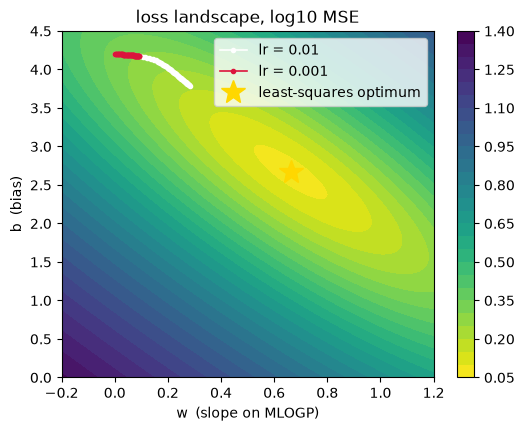

after 60 steps:  lr=0.01 → w=0.282 b=3.787  |  lr=0.001 → w=0.092 b=4.172  |  optimum w=0.662 b=2.668


In [ ]:
path_ok = gradient_descent(0.0, 4.2, lr=0.01)
path_slow = gradient_descent(0.0, 4.2, lr=0.001)

fig, ax = plt.subplots(figsize=(6, 4.5))
cs = ax.contourf(ws, bs, np.log10(L), levels=30, cmap="viridis_r")
ax.plot(*path_ok.T, "o-", c="white", ms=3, lw=1.2, label="lr = 0.01")
ax.plot(*path_slow.T, "o-", c="crimson", ms=3, lw=1.2, label="lr = 0.001")
ax.plot(lin1.coef_[0], lin1.intercept_, "*", c="gold", ms=18, label="least-squares optimum")
ax.set_xlabel("w  (slope on MLOGP)"); ax.set_ylabel("b  (bias)")
ax.set_title("loss landscape, log10 MSE")
ax.legend(loc="upper right")
fig.colorbar(cs, ax=ax)
plt.show()

print("after 60 steps:  lr=0.01 → w=%.3f b=%.3f  |  lr=0.001 → w=%.3f b=%.3f  |  optimum w=%.3f b=%.3f"
      % (*path_ok[-1], *path_slow[-1], lin1.coef_[0], lin1.intercept_))

✏️ **Exercise 3.** Re-run `gradient_descent` with `lr=0.05` and then `lr=0.2`. What happens, and what
does the landscape tell you about why?

In [ ]:
for lr in [0.01, 0.05, 0.2]:
    p = gradient_descent(0.0, 4.2, lr=lr, steps=60)
    w_, b_ = p[-1]
    final = np.mean((w_ * m_ + b_ - y_) ** 2)
    print(f"lr={lr:<5}  w={w_:8.3f}  b={b_:8.3f}  MSE={final:,.3f}"
          + ("   ← diverged" if not np.isfinite(final) or final > 100 else ""))

lr=0.01   w=   0.282  b=   3.787  MSE=1.615
lr=0.05   w=   0.567  b=   2.947  MSE=1.243
lr=0.2    w=-4430185416333150.000  b=-1503176916428909.250  MSE=157,941,292,857,317,655,274,354,720,636,928.000   ← diverged


**Answer.** `lr=0.05` converges faster than 0.01; `lr=0.2` diverges to infinity. The valley in the
contour plot is a long, narrow ellipse - steep across, nearly flat along - because `MLOGP` is not
centred. A step that is sensible along the valley is far too large across it, so the iterate bounces
between the walls, each bounce bigger than the last.

This is the practical reason inputs get standardised before training, and the reason modern optimizers
(Adam, and the batch-normalisation layer pictured on slide 23) scale each direction separately. Nothing
about a "neural" network is involved: it is the geometry of a quadratic.

## Part 5 - Many neurons: a network

Slide 14 counts the parameters of a tiny network: `k` inputs, `N` neurons in a layer,
`nw = N(k+1)` weights. Slide 15 makes the universal-approximation claim - enough neurons and the right
weights approximate arbitrary functions - and slide 13 immediately attaches the price tag: *computing
cost, data hunger, overfitting* 👻.

We have 908 molecules and 6 descriptors. Let us buy neurons and see what we get.

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for h in [1, 2, 5, 20, 100]:
    mlp = make_pipeline(StandardScaler(),
                        MLPRegressor(hidden_layer_sizes=(h,), max_iter=2000, random_state=RNG))
    r2 = cross_val_score(mlp, X, y, cv=cv, scoring="r2").mean()
    rows.append({"hidden units": h, "parameters": h * (6 + 1) + (h + 1), "CV R2": round(r2, 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nlinear regression, same folds: CV R2 =", round(cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2').mean(), 3))

 hidden units  parameters  CV R2
            1           9  0.557
            2          17 -0.019
            5          41  0.577
           20         161  0.598
          100         801  0.571

linear regression, same folds: CV R2 = 0.557


❓ **Question.** Three things in that table are worth explaining. Why does **1 hidden unit** score the
same as linear regression? Why does **2** collapse? And why does **100** not beat **20**?

**Answer.**

- **1 unit → 0.557, exactly the linear score.** With a single hidden neuron the network can only output a
  rescaled, once-bent version of one linear combination of the inputs - Part 3's result, restated. The
  kink again lands outside the data, so it *is* a linear regression.
- **2 units → -0.019, worse than predicting the mean.** This is not a capacity limit, it is an
  optimization failure: with ReLU activations a narrow layer can land in a state where both units output
  zero for every training molecule ("dead ReLUs"), the gradient is then zero, and training stops. Change
  the seed and it sometimes recovers. Slide 15 says a network *may* approximate arbitrary functions
  **with the correct weights** - finding them is a separate, non-convex problem, and this row is what the
  caveat looks like in practice.
- **100 units → 0.571, below 20 units' 0.598.** We have 908 rows and six descriptors. Extra capacity
  cannot invent information that is not in the data; it only adds ways to fit the noise. The ceiling here
  is set by the data, not by the architecture.

Deep learning's famous wins came with 10⁵-10⁹ training examples. On a 908-row table, a neural network is
a reasonable model and not a magic one - which is exactly the "orders of magnitude" literacy that
slide 63 asks you to take home.

## Part 6 - Overfitting, and why the test set exists

Slide 19 shows two curves through the same points and asks which you prefer. Slide 21 draws the answer:
the training loss keeps falling while the test loss turns around.

Let us produce that figure from our own data. We take a deliberately oversized network - two layers of
256 units, ~70,000 parameters for 681 training molecules - and record both losses after every epoch.

In [ ]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=RNG)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

net = MLPRegressor(hidden_layer_sizes=(256, 256), alpha=1e-7, max_iter=1, warm_start=True,
                   learning_rate_init=3e-3, random_state=RNG)

train_loss, test_loss = [], []
for epoch in range(400):
    net.fit(Xtr_s, ytr)                       # warm_start: one more epoch each time
    train_loss.append(np.mean((net.predict(Xtr_s) - ytr) ** 2))
    test_loss.append(np.mean((net.predict(Xte_s) - yte) ** 2))

best = int(np.argmin(test_loss))
print(f"parameters: {sum(c.size for c in net.coefs_) + sum(i.size for i in net.intercepts_):,}"
      f"   training molecules: {len(ytr)}")
print(f"best epoch {best + 1}: train MSE {train_loss[best]:.3f}, test MSE {test_loss[best]:.3f}")
print(f"epoch 400:     train MSE {train_loss[-1]:.3f}, test MSE {test_loss[-1]:.3f}")

parameters: 67,841   training molecules: 681
best epoch 218: train MSE 0.292, test MSE 0.885
epoch 400:     train MSE 0.231, test MSE 1.109


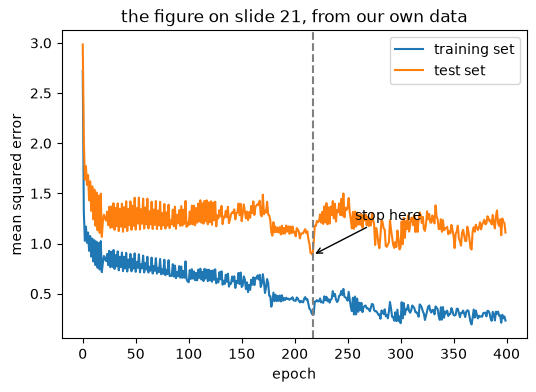

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(train_loss, label="training set")
ax.plot(test_loss, label="test set")
ax.axvline(best, ls="--", c="grey")
ax.annotate("stop here", (best, test_loss[best]), xytext=(best + 40, test_loss[best] + 0.35),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("epoch"); ax.set_ylabel("mean squared error")
ax.set_title("the figure on slide 21, from our own data")
ax.legend()
plt.show()

Training error falls to 0.231 and keeps going; test error bottoms out at 0.885 around epoch 218 and then
climbs to 1.109. Past that point the network is memorising its 681 molecules. That is slide 19's green
curve, drawn by a real optimizer.

❓ **Question (read slide 21 critically).** The slide says training stops "when loss on the test set is
minimized". We just did that. What is now wrong with calling 0.885 our estimate of how the model will
perform on new chemicals?

**Answer.** We chose a hyperparameter - when to stop - by looking at the test set, so the test set helped
build the model and is no longer independent of it. The reported 0.885 is the *minimum* of a noisy curve,
which is optimistically biased for the same reason the maximum of 400 coin-flip runs is not a fair
estimate of a coin.

The fix is three splits: **train** to fit the weights, **validation** to pick when to stop and how wide
to go, **test** touched exactly once at the end. Slide 21's two-way picture is the right intuition and
the wrong protocol, and the distinction is the single most common hole in a student thesis.

How badly does a single split mislead? Repeat the plain linear fit on 200 different random 75/25 splits:

R2 from one 75/25 split: mean 0.566, min 0.408, max 0.686


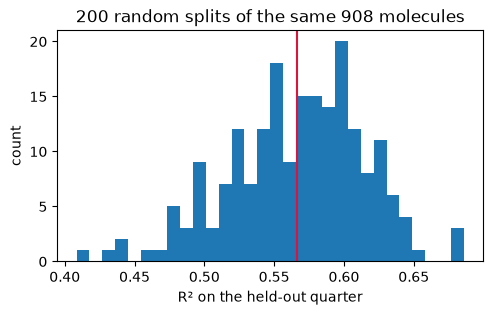

In [ ]:
singles = []
for seed in range(200):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, random_state=seed)
    singles.append(LinearRegression().fit(Xa, ya).score(Xb, yb))
print("R2 from one 75/25 split: mean %.3f, min %.3f, max %.3f" % (np.mean(singles), min(singles), max(singles)))

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.hist(singles, bins=30)
ax.axvline(np.mean(singles), c="crimson")
ax.set_xlabel("R² on the held-out quarter"); ax.set_ylabel("count")
ax.set_title("200 random splits of the same 908 molecules")
plt.show()

The same model, the same data, and the answer ranges from 0.41 to 0.69 depending on which quarter you
happened to hold out. Quoting one split to three decimals - as papers routinely do - is reporting a draw
from this histogram. Use cross-validation, and report the spread, not just the mean.

## Part 7 - Featurization: the model is only as good as its inputs

Slide 25 asks what you do when the inputs are not already a row of numbers - molecules, structures,
surfaces, images - and lists the usual answers in chemoinformatics: descriptors, fingerprints, SMILES
strings, graphs. Our six descriptors *are* such a featurization; somebody chose them, and that choice
caps everything we have done today.

Two quick controls make the point.

In [ ]:
rng = np.random.default_rng(RNG)

control = {
    "real descriptors": cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2").mean(),
    "6 random numbers per molecule": cross_val_score(
        LinearRegression(), rng.normal(size=X.shape), y, cv=cv, scoring="r2").mean(),
    "real descriptors, shuffled labels": cross_val_score(
        LinearRegression(), X, rng.permutation(y), cv=cv, scoring="r2").mean(),
}
for k, v in control.items():
    print(f"{k:>35s}:  CV R2 = {v:+.3f}")

                   real descriptors:  CV R2 = +0.557
      6 random numbers per molecule:  CV R2 = -0.018
  real descriptors, shuffled labels:  CV R2 = -0.008


Both controls land at about **0.0** - slightly negative, since a model fitted on noise is worse than
predicting the mean. Useful calibration: **R² = 0 is what "learned nothing" looks like**, and a
cross-validated R² of 0.56 from six cheap numbers is a genuine signal, not an artefact of the machinery.

Run a control like this every time a model surprises you. It costs one line and it is the difference
between a result and a bug.

❓ **Question.** We spent the session on *which model* (line, neuron, network of 20, network of 100) and
the spread was 0.56 to 0.60. What would you change if you wanted 0.8?

**Answer.** Not the model - the representation, or the data. Six descriptors are a lossy summary of a
molecule: two different compounds with the same six numbers are indistinguishable to every model in this
notebook, no matter how deep. Better options, in increasing order of effort: more descriptors
(deephERG, slide 50, uses 185 plus 100 learned embeddings); fingerprints or a graph representation that
keeps the topology; a representation **learned** from data rather than hand-crafted - which is precisely
the argument for CNNs on slide 29 and for pretrained models on slides 36-44.

That is where classes 2 and 3 go: class 2 lets the network learn its own features from raw sequence,
class 3 borrows features from a model pretrained on 250 million proteins.

## Summary

| slide | claim | what we measured |
|---|---|---|
| 6-7 | regression is induction under an assumed functional form | linear fit, CV R² 0.56 |
| 8, 24 | the induced coefficients are themselves informative | MLOGP +0.39 per unit, interpretable |
| 10-11 | a neuron = linear regression + nonlinearity | identity neuron ≡ `LinearRegression` to 1e-15 |
| 17, 22-23 | training = gradient descent on a loss | the landscape, and divergence at lr = 0.2 |
| 13-15 | more neurons ⇒ more capacity, at a price | width 20 best (0.598); 100 worse; 2 fails to train |
| 19-21 | overfitting, and the test set | test MSE turns around at epoch 218, 0.885 → 1.109 |
| 21 | *stop when the test loss is minimised* | true, but then that test score is biased - use 3 splits |
| 25 | featurization caps the result | random features give R² ≈ 0; six good ones give 0.56 |

**The one-line version.** A neural network is a stack of regressions fitted by walking downhill, it needs
more data than this table has, and the thing that limits your result is usually the representation, not
the architecture.

## Your turn: water fleas (homework)

`load_aquatic()` gives 546 chemicals with 8 descriptors and their 48-hour LC50 for *Daphnia magna*.

1. Repeat Parts 2 and 5: linear regression, then MLPs of a few widths, 5-fold cross-validated. (A plain
   linear fit gets CV R² ≈ 0.46 - use that to check your pipeline.)
2. `MLOGP` appears in both datasets. Is its coefficient similar for fish and for *Daphnia*? Should it be?
3. Harder, and the question a regulator would ask: train on the fish data and predict the *Daphnia*
   labels for the chemicals the two datasets have in common. You will need to decide how to match
   molecules when all you have are descriptors - and the difficulty of that step is itself the lesson.

## References and data sources

**Data.**
- M. Cassotti, D. Ballabio, R. Todeschini, V. Consonni, *A similarity-based QSAR model for predicting
  acute toxicity towards the fathead minnow (Pimephales promelas)*, SAR QSAR Environ. Res. 26 (2015)
  217-243. UCI ML Repository, "QSAR fish toxicity"
  (https://archive.ics.uci.edu/dataset/504/qsar+fish+toxicity).
- M. Cassotti, D. Ballabio, V. Consonni, A. Mauri, I. V. Tetko, R. Todeschini, *Prediction of acute
  aquatic toxicity toward Daphnia magna by using the GA-kNN method*, ATLA 42 (2014) 31-41. UCI ML
  Repository, "QSAR aquatic toxicity".

**Mentioned in the slides.**
- 3Blue1Brown, *Neural networks* (video series) - the backpropagation illustration on slide 23.
- A. Cherkasov *et al.*, *QSAR modeling: where have you been? Where are you going to?*,
  J. Med. Chem. 57 (2014) 4977 - context for what these descriptors are.
- A. D. White, *Deep Learning for Molecules and Materials*, dmol.pub - slide 65's self-study
  recommendation, and the natural next step after this notebook.

**Software.** scikit-learn (Pedregosa *et al.*, JMLR 12 (2011) 2825), numpy, pandas, matplotlib.

**Related notebooks in this repository.** `course/t01_toxicity_qsar.ipynb` works the same dataset at
greater length (PCA, kNN and random forests, learning curves, permutation importance);
`course/extra01_scaling_laws.ipynb` makes the same points about fitting on physiological data, with no
toxicology.